In [7]:
from pathlib import Path
import sys

# Add the parent directory of the current working directory to the Python path
repo_root = Path.cwd().parent
sys.path.insert(0, str(repo_root))

from fp_scripts.visualize_fp import plot_focalplane_primecam
from fp_scripts.module_to_boresight import ModuleToBoresightOffset

In [18]:
from astropy.table import QTable, vstack
from toast.instrument import Focalplane
import matplotlib.pyplot as plt
import astropy.units as u

In [5]:
help(plot_focalplane_primecam)

Help on function plot_focalplane_primecam in module fp_scripts.visualize_fp:

plot_focalplane_primecam(focalplane=None, width=None, height=None, outfile=None, show_labels=False, face_color=None, pol_color=None, xieta=False, show_centers=False, show_gamma=False)
    Visualize a projected Primecam Module Focalplane. This is a modified version of the
    TOAST function plot_focalplane.

    This makes a simple plot of the detector positions on the projected focalplane.
    By default, this plots the focalplane in the boresight X / Y / Z frame, as seen
    by incoming photons.  If `xieta` is set to True, the focalplane is plotted in
    Xi / Eta / Gamma coordinates as seen from the observer looking out at the sky.

    To avoid python overhead in large MPI jobs, we place the matplotlib import inside
    this function, so that it is only imported when the function is actually called.

    Args:
        focalplane (Focalplane):  The focalplane to plot
        width (Quantity):  Width of plot

In [6]:
!ls ../fp_files/

primecam_f280_dettable.h5  primecam_f_fake1_dettable.h5
primecam_f350_dettable.h5  primecam_f_fake2_dettable.h5
primecam_f420_dettable.h5  primecam_f_fake3_dettable.h5
primecam_f850_dettable.h5


### Single module example

In [2]:
hf_fulltable_file = "../fp_files/primecam_f280_dettable.h5"
# hf_fulltable_file = "../fp_files/fp_f280_dettable_test_ps17.h5"
dettable_stack = QTable.read(hf_fulltable_file, path='dettable_stack')

# hf_fulltable_file = "./dets_FP_PC280_10_w2.h5"
# dettable_stack = QTable.read(hf_fulltable_file, path='dettable_trim') 

In [3]:
# width= 1.3 * u.degree
width= 4.5 * u.degree
fp_test =  Focalplane(
                detector_data=dettable_stack)

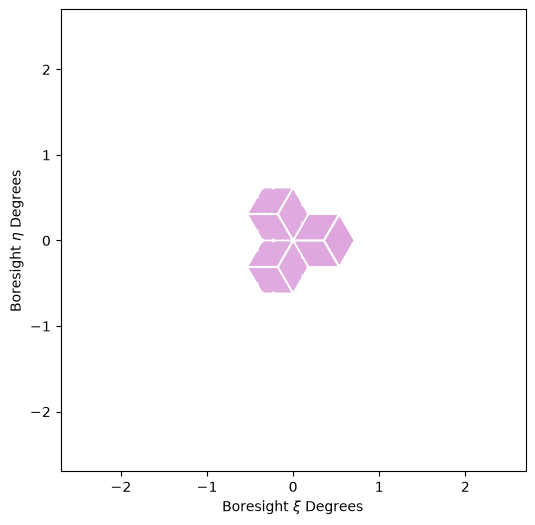

In [4]:
plot_focalplane_primecam(
    focalplane=fp_test,
    xieta=True,
    width=width,
    height=width,
    show_labels=False,
    # outfile="fp_280gz_test.pdf"
)
plt.show()

### Prime-Cam full focal plane

In [13]:
help(ModuleToBoresightOffset)

Help on class ModuleToBoresightOffset in module fp_scripts.module_to_boresight:

class ModuleToBoresightOffset(builtins.object)
 |  ModuleToBoresightOffset(module_name: 'str', config_path: 'str | Path' = PosixPath('/home/anks/Projects/CCAT/primecam_focalplane/fp_scripts/fp_config.yaml'), clocking_deg: 'float | None' = None) -> 'None'
 |
 |  Load and place one module's detector table in the boresight frame.
 |
 |  :meth:`apply` returns a copied QTable in which ``module_quat`` is relative
 |  to the module center and ``quat`` is relative to the FYST boresight.  No
 |  file is written.
 |
 |  Example
 |  -------
 |  Use the module's assigned position (currently ``primecam_f280 -> i6``)::
 |
 |      module_offset = ModuleToBoresightOffset("primecam_f280")
 |      detector_table = module_offset.apply()
 |
 |  Methods defined here:
 |
 |  __init__(self, module_name: 'str', config_path: 'str | Path' = PosixPath('/home/anks/Projects/CCAT/primecam_focalplane/fp_scripts/fp_config.yaml'), clockin

In [14]:
f280module_offset = ModuleToBoresightOffset("primecam_f280")
detector_table_f280 = f280module_offset.apply()

In [15]:
f350module_offset = ModuleToBoresightOffset("primecam_f350")
detector_table_f350 = f350module_offset.apply()

In [16]:
f420module_offset = ModuleToBoresightOffset("primecam_f420")
detector_table_f420 = f420module_offset.apply()

In [17]:
f850module_offset = ModuleToBoresightOffset("primecam_f850")
detector_table_f850 = f850module_offset.apply()

f_fake1module_offset = ModuleToBoresightOffset("primecam_f_fake1")
detector_table_f_fake1 = f_fake1module_offset.apply()

f_fake2module_offset = ModuleToBoresightOffset("primecam_f_fake2")
detector_table_f_fake2 = f_fake2module_offset.apply()

f_fake3module_offset = ModuleToBoresightOffset("primecam_f_fake3")
detector_table_f_fake3 = f_fake3module_offset.apply()

In [19]:
detector_table_combined = vstack(
    [detector_table_f280, detector_table_f350, detector_table_f420,
     detector_table_f850, detector_table_f_fake1, detector_table_f_fake2, detector_table_f_fake3],
    metadata_conflicts="silent",
)

In [20]:
detector_table_combined[:-10]

name,quat,module,wafer_slot,band,pixel,pol,psi_pol,gamma,fwhm,psd_fmin,psd_fknee,psd_alpha,psd_net,bandcenter,bandwidth,index,module_quat
,,,,,,,rad,rad,arcmin,Hz,Hz,,K s(1/2),GHz,GHz,,
bytes21,float64[4],bytes16,bytes2,bytes7,bytes4,bytes5,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64[4]
w1_p0000_PC_f280_A,-0.020591777771935514 .. 0.8658439567711165,primecam_f280,w1,PC_f280,0000,A,0.0,-4.188797610336008,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,0,-0.005061097595660121 .. 0.8660164185382206
w1_p0000_PC_f280_B,-0.014567185885368887 .. 0.9657198899643751,primecam_f280,w1,PC_f280,0000,B,1.5707963267948966,-2.61800128354111,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,1,-0.0035853836840607496 .. 0.9659123648693935
w1_p0001_PC_f280_A,-0.01891040329494167 .. 0.991237159344061,primecam_f280,w1,PC_f280,0001,A,0.0,-3.4033991249541486,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,2,-0.004561928745215137 .. 0.9914332012233316
w1_p0001_PC_f280_B,-0.007794738078175958 .. 0.7931847988868194,primecam_f280,w1,PC_f280,0001,B,1.5707963267948966,-1.832602798159252,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,3,-0.0018514489041008483 .. 0.7933411187370976
w1_p0002_PC_f280_A,-0.01895575389936964 .. 0.9912374403047227,primecam_f280,w1,PC_f280,0002,A,0.0,-3.4033991249554654,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,4,-0.004607286738995648 .. 0.9914332418946568
w1_p0002_PC_f280_B,-0.007904225081770435 .. 0.7931834825268456,primecam_f280,w1,PC_f280,0002,B,1.5707963267948966,-1.8326027981605688,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,5,-0.0019609537153393664 .. 0.7933409230201899
w1_p0003_PC_f280_A,-0.020386523543465335 .. 0.8658465149737459,primecam_f280,w1,PC_f280,0003,A,0.0,-4.188796966367739,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,6,-0.004855802885766496 .. 0.8660171359368656
w1_p0003_PC_f280_B,-0.014338250737499844 .. 0.965724506085482,primecam_f280,w1,PC_f280,0003,B,1.5707963267948966,-2.6180006395728426,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,7,-0.003356406308290832 .. 0.9659134247672867


In [23]:
width= 4.5 * u.degree
fp_test =  Focalplane(
                detector_data=detector_table_combined)

plot_focalplane_primecam(
    focalplane=fp_test,
    xieta=True,
    face_color={"primecam_f280": "plum", "primecam_f350": "skyblue",
                 "primecam_f420": "palegreen", "primecam_f850": "peru",
                 "primecam_f_fake1": "tan", "primecam_f_fake2": "khaki",
                 "primecam_f_fake3": "slateblue"},
    width=width,
    height=width,
    show_labels=False,
    outfile="../plots/fp_primecam_tube.pdf"
)
plt.show()